In [14]:
# import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("Telco_Customer_Churn_Dataset  (3).csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [15]:
df.info

<bound method DataFrame.info of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service             DSL 

In [16]:
# Check the dataset size, column names and data types
print("Dataset shape:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

Dataset shape: (7043, 21)
\nColumn names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
\nData types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-nu

In [17]:
# Convert column names to lowercase and replace spaces with underscores
df.columns = (df.columns
              .str.strip()
              .str.lower()
              .str.replace(r"\\s+", "_", regex=True))

print(df.columns.tolist())

['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents', 'tenure', 'phoneservice', 'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod', 'monthlycharges', 'totalcharges', 'churn']


In [18]:
df.info

<bound method DataFrame.info of       customerid  gender  seniorcitizen partner dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     phoneservice     multiplelines internetservice onlinesecurity  ...  \
0              No  No phone service             DSL 

In [19]:
df.isnull().sum()

customerid          0
gender              0
seniorcitizen       0
partner             0
dependents          0
tenure              0
phoneservice        0
multiplelines       0
internetservice     0
onlinesecurity      0
onlinebackup        0
deviceprotection    0
techsupport         0
streamingtv         0
streamingmovies     0
contract            0
paperlessbilling    0
paymentmethod       0
monthlycharges      0
totalcharges        0
churn               0
dtype: int64

In [20]:
df.describe()

,seniorcitizen,tenure,monthlycharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [21]:
# Missing values in each column
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})
missing_summary.sort_values("missing_count", ascending=False)

,missing_count,missing_percent
customerid,0,0.0
gender,0,0.0
seniorcitizen,0,0.0
partner,0,0.0
dependents,0,0.0
tenure,0,0.0
phoneservice,0,0.0
multiplelines,0,0.0
internetservice,0,0.0
onlinesecurity,0,0.0


In [22]:
# Number of duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Review categorical values and possible inconsistencies
df.describe(include="all").T

Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerid,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seniorcitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
phoneservice,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
multiplelines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
internetservice,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
onlinesecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
# In the common Telco Customer Churn dataset, totalcharges may be read as text
if "totalcharges" in df.columns:
    df["totalcharges"] = pd.to_numeric(df["totalcharges"], errors="coerce")

# Identify numeric columns
numeric_cols = df.select_dtypes(include="number").columns.tolist()
print("Numerical columns:", numeric_cols)

Numerical columns: ['seniorcitizen', 'tenure', 'monthlycharges', 'totalcharges']


In [24]:
if numeric_cols:
    display(df[numeric_cols].isna().sum().rename("missing_after_conversion").to_frame())

,missing_after_conversion
seniorcitizen,0
tenure,0
monthlycharges,0
totalcharges,11


In [25]:
# Mean and median for all numeric columns
summary = pd.DataFrame({
    "mean": df[numeric_cols].mean(),
    "median": df[numeric_cols].median()
})

# Mode can have more than one value; report the first mode for each column
summary["mode"] = df[numeric_cols].mode().iloc[0] if numeric_cols else pd.Series(dtype="object")

summary.round(2)

,mean,median,mode
seniorcitizen,0.16,0.00,0.00
tenure,32.37,29.00,1.00
monthlycharges,64.76,70.35,20.05
totalcharges,2283.30,1397.48,20.20


In [26]:
# Additional descriptive statistics: count, standard deviation, minimum and quartiles
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
seniorcitizen,7043.0,0.162147,0.368612,0.00,0.00,0.000,0.0000,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
monthlycharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
totalcharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


In [27]:
df['totalcharges'].isnull().sum()

np.int64(11)

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

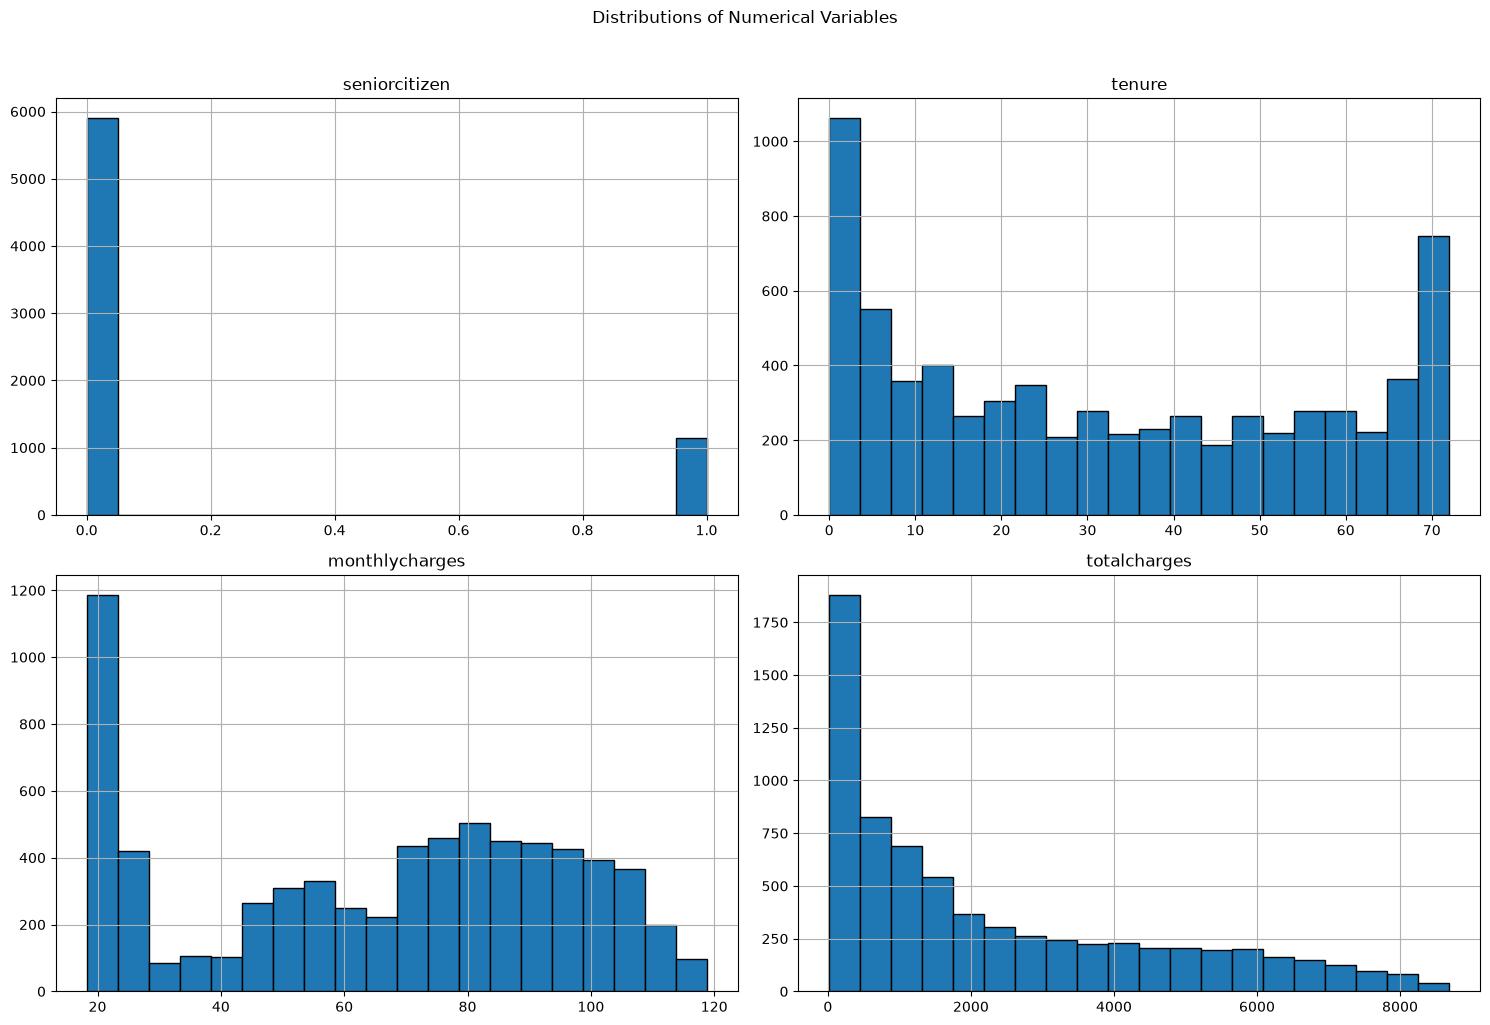

In [29]:
# Create one histogram for each numeric column
if numeric_cols:
    df[numeric_cols].hist(
        figsize=(15, 10),
        bins=20,
        edgecolor="black"
    )
    plt.suptitle("Distributions of Numerical Variables", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No numerical columns were detected.")

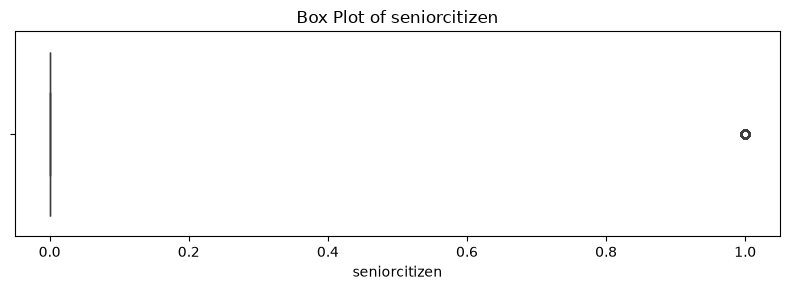

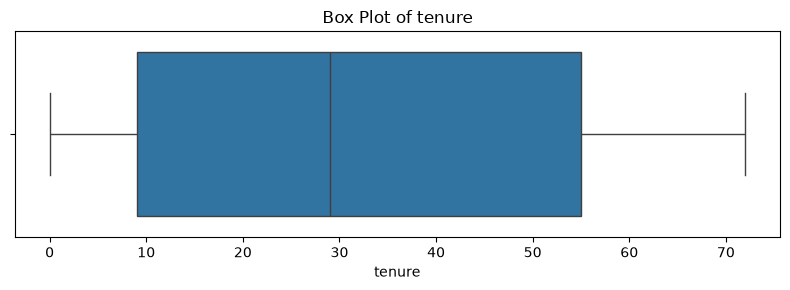

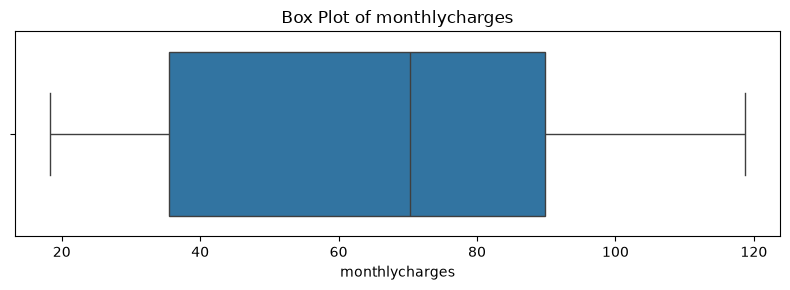

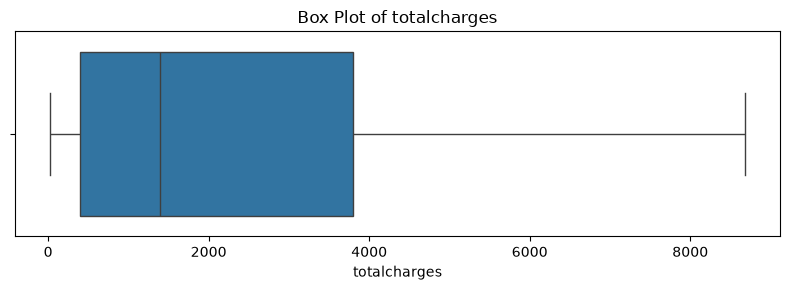

In [30]:
# Separate box plots make variables with different scales easier to inspect
for col in numeric_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Box Plot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

In [ ]:
# Find a likely churn column, or set it manually
possible_churn_cols = [col for col in df.columns if col in ["churn", "customer_churn"]]
print("Possible churn columns:", possible_churn_cols)

# Set the correct column name from the output above
churn_col = "churn"

if churn_col not in df.columns:
    raise KeyError(f"'{churn_col}' was not found. Check df.columns and update churn_col.")

# Counts and percentages, including missing values
churn_counts = df[churn_col].value_counts(dropna=False)
churn_percentages = df[churn_col].value_counts(normalize=True, dropna=False).mul(100)

churn_summary = pd.DataFrame({
    "customer_count": churn_counts,
    "percentage": churn_percentages.round(2)
})
churn_summary

Possible churn columns: ['churn']


,customer_count,percentage
churn,,
No,5174,73.46
Yes,1869,26.54


In [45]:
# Analyze churn rates (e.g., churn vs. non-churn proportions).
possible_churn_cols = [col for col in df.columns if col in ["churn", "customer_churn"]]
print("Possible churn columns:", possible_churn_cols)

df['churn'].value_counts()

churn_summary = pd.DataFrame({
    "customer_count": churn_counts,
    "percentage": churn_percentages.round(2)
})
churn_summary

Possible churn columns: ['churn']


,customer_count,percentage
churn,,
No,5174,73.46
Yes,1869,26.54


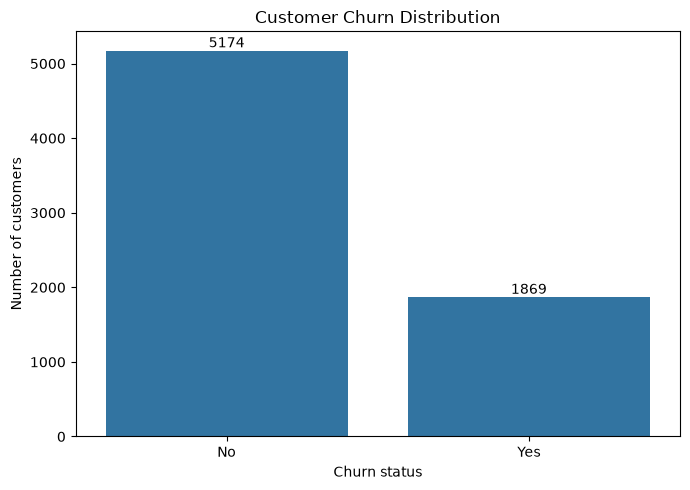

In [ ]:
# Bar chart: compare the number of customers in each churn category
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x=churn_col, order=df[churn_col].value_counts().index)

for container in ax.containers:
    ax.bar_label(container)
    
plt.title("Customer Churn Distribution")
plt.xlabel("Churn status")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

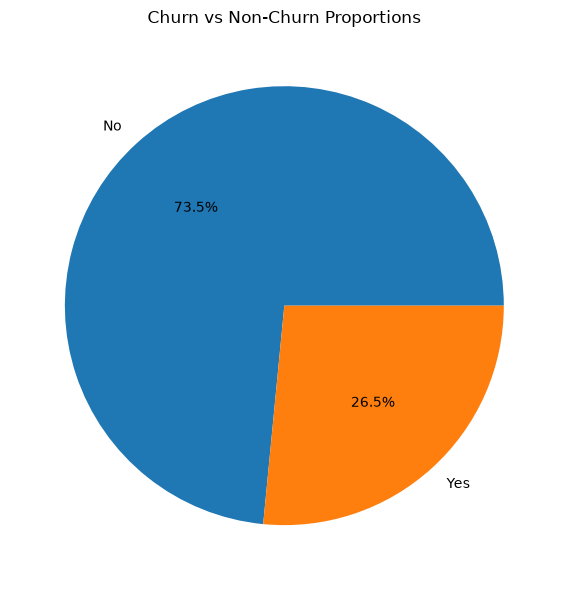

In [ ]:
# Optional pie chart: share of customers in each churn category
churn_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(6, 6),
    ylabel=""
)
plt.title("Churn vs Non-Churn Proportions")
plt.tight_layout()
plt.show()

In [ ]:
# Compare numeric averages across churn categories
df.groupby(churn_col)[numeric_cols].mean().T.round(2)

churn,No,Yes
seniorcitizen,0.13,0.25
tenure,37.57,17.98
monthlycharges,61.27,74.44
totalcharges,2555.34,1531.80


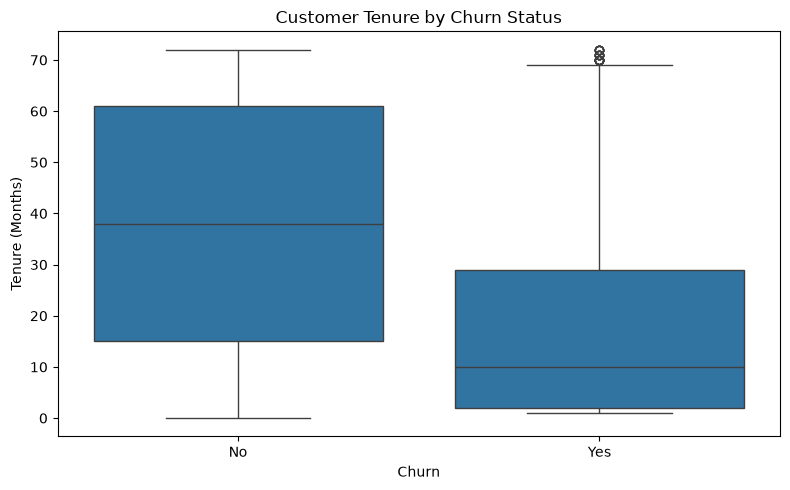

In [ ]:
### Tenure and churn
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="churn", y="tenure", order=["No", "Yes"])
plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

In [ ]:
# Create tenure categories
df['tenure_category'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 36, float('inf')],
    labels=['0-12 Months', '13-36 Months', '37+ Months']
)

# Count customers in each tenure category
tenure_distribution = df['tenure_category'].value_counts().sort_index()

print(tenure_distribution)

tenure_category
0-12 Months     2186
13-36 Months    1856
37+ Months      3001
Name: count, dtype: int64


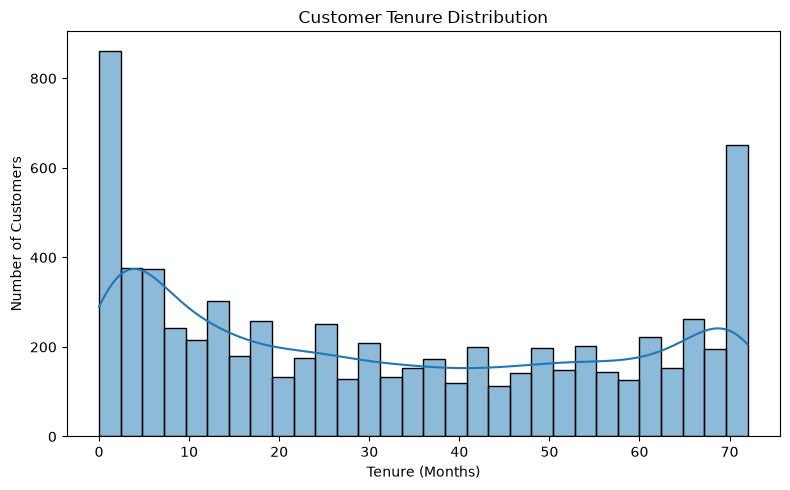

In [49]:
plt.figure(figsize=(8, 5))
sns.histplot(
    df['tenure'],
    bins=30,
    kde=True
)
for container in ax.containers:
    ax.bar_label(container)
    
plt.title("Customer Tenure Distribution")
plt.xlabel('Tenure (Months)')
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

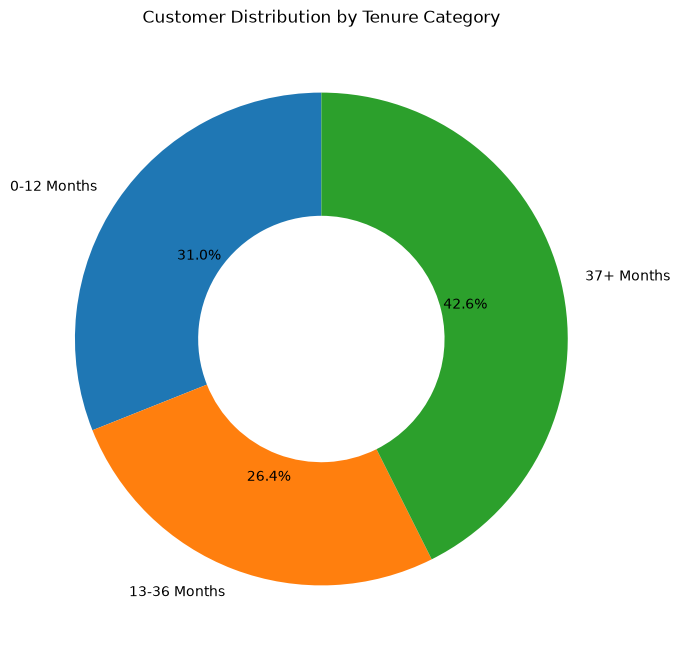

In [ ]:
# Visualize customer distribution by tenure using pie or donut charts.
# (e.g., 0-12 months, 13-36 months, 37+ months).
plt.figure(figsize=(8, 8))

plt.pie(
    tenure_distribution,
    labels=tenure_distribution.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.5}
)

plt.title('Customer Distribution by Tenure Category')
plt.show()

tenure_category
0-12 Months     56.10
13-36 Months    63.25
37+ Months      72.01
Name: monthlycharges, dtype: float64

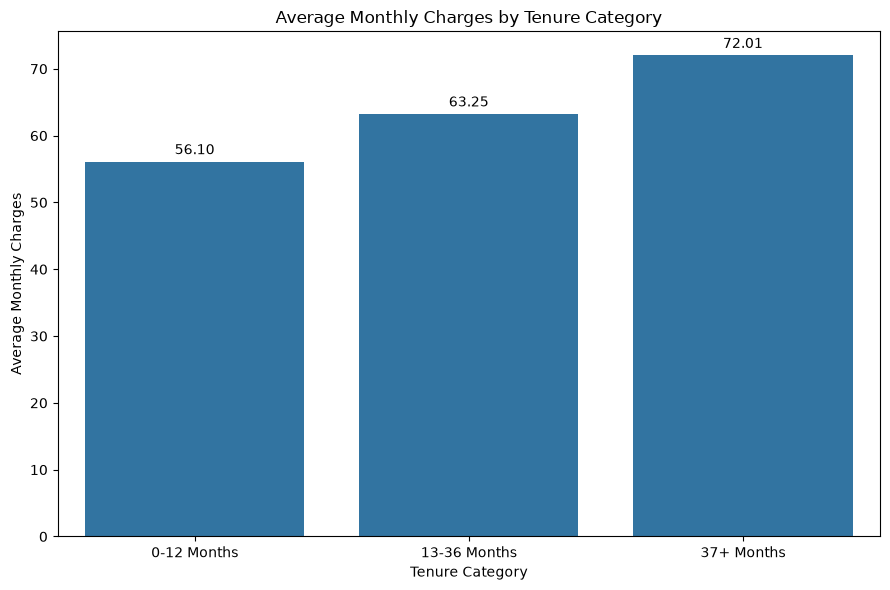

In [ ]:
## Average monthly charges across tenure categories
monthly_charges_by_tenure = (
    df.groupby("tenure_category", observed=False)["monthlycharges"]
    .mean()
)

display(monthly_charges_by_tenure.round(2))

plt.figure(figsize=(9, 6))
ax = sns.barplot(
    x=monthly_charges_by_tenure.index,
    y=monthly_charges_by_tenure.values
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Average Monthly Charges by Tenure Category")
plt.xlabel("Tenure Category")
plt.ylabel("Average Monthly Charges")
plt.tight_layout()
plt.show()

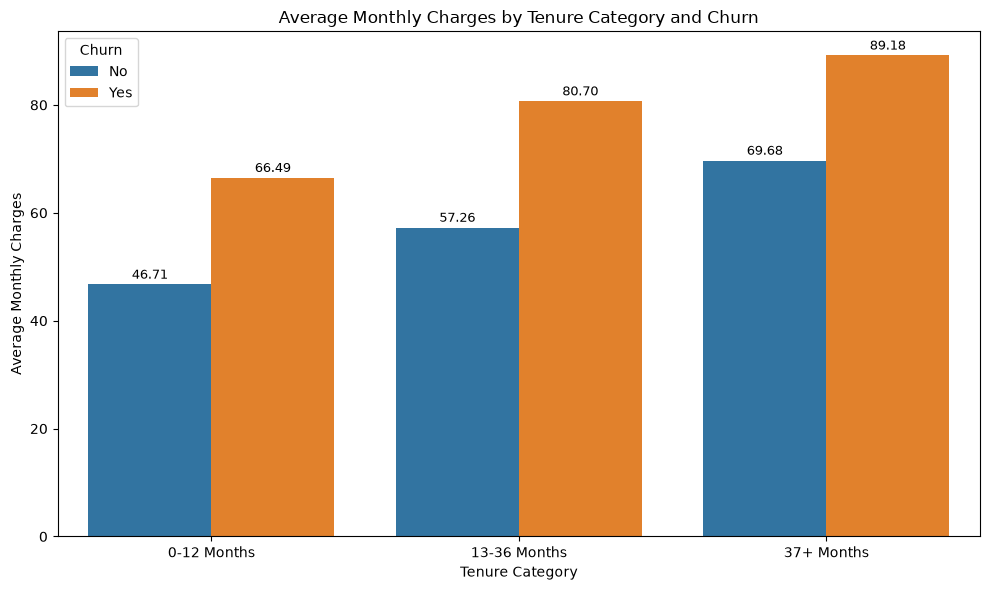

In [ ]:
## Clustered bar chart: average monthly charges by tenure and churn
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=df,
    x="tenure_category",
    y="monthlycharges",
    hue="churn",
    order=["0-12 Months", "13-36 Months", "37+ Months"],
    hue_order=["No", "Yes"],
    errorbar=None
)

# Add average values to each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=9)

plt.title("Average Monthly Charges by Tenure Category and Churn")
plt.xlabel("Tenure Category")
plt.ylabel("Average Monthly Charges")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [ ]:
## Explore churn rate within each tenure category
churn_by_tenure = pd.crosstab(
    df["tenure_category"],
    df["churn"],
    normalize="index"
) * 100

churn_by_tenure = churn_by_tenure.round(2)
display(churn_by_tenure)

churn,No,Yes
tenure_category,,
0-12 Months,52.56,47.44
13-36 Months,74.46,25.54
37+ Months,88.07,11.93


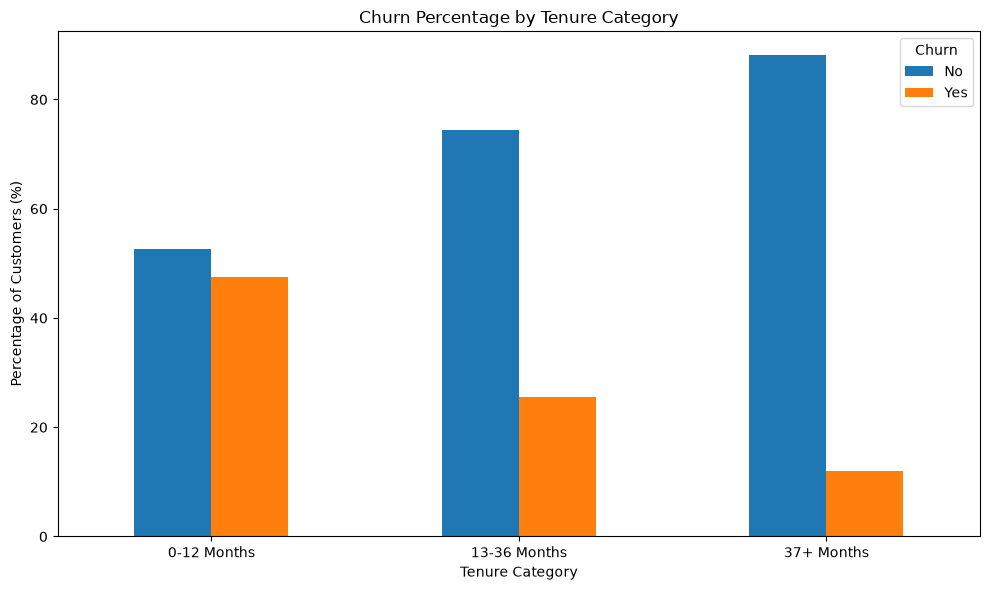

In [ ]:
churn_by_tenure.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Churn Percentage by Tenure Category")
plt.xlabel("Tenure Category")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

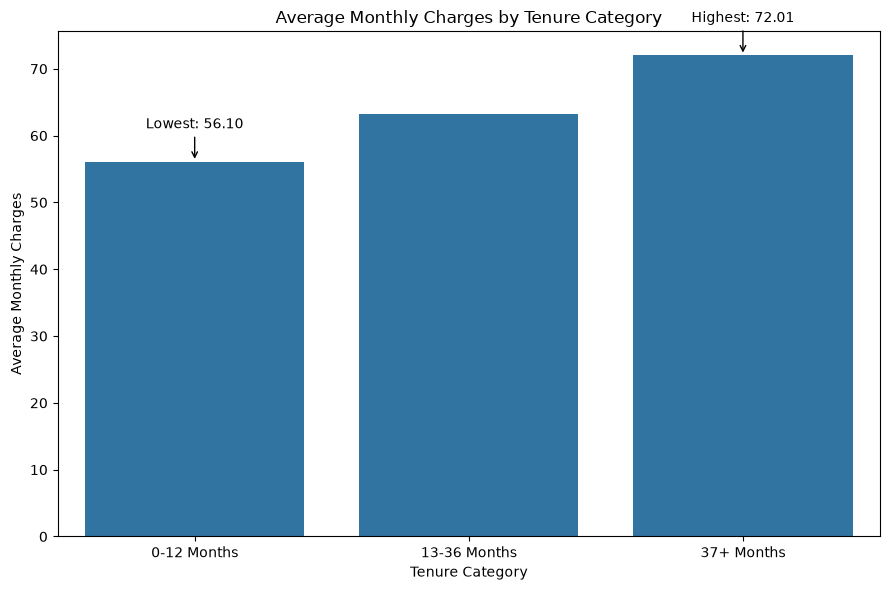

Highest average: 37+ Months — 72.01
Lowest average: 0-12 Months — 56.10


In [ ]:
## Highlight highest and lowest average monthly charges
plt.figure(figsize=(9, 6))
ax = sns.barplot(
    x=monthly_charges_by_tenure.index,
    y=monthly_charges_by_tenure.values
)

highest_category = monthly_charges_by_tenure.idxmax()
lowest_category = monthly_charges_by_tenure.idxmin()

highest_index = monthly_charges_by_tenure.index.get_loc(highest_category)
lowest_index = monthly_charges_by_tenure.index.get_loc(lowest_category)

highest_value = monthly_charges_by_tenure.max()
lowest_value = monthly_charges_by_tenure.min()

ax.annotate(
    f"Highest: {highest_value:.2f}",
    xy=(highest_index, highest_value),
    xytext=(highest_index, highest_value + 5),
    ha="center",
    arrowprops={"arrowstyle": "->"}
)

ax.annotate(
    f"Lowest: {lowest_value:.2f}",
    xy=(lowest_index, lowest_value),
    xytext=(lowest_index, lowest_value + 5),
    ha="center",
    arrowprops={"arrowstyle": "->"}
)

plt.title("Average Monthly Charges by Tenure Category")
plt.xlabel("Tenure Category")
plt.ylabel("Average Monthly Charges")
plt.tight_layout()
plt.show()

print(f"Highest average: {highest_category} — {highest_value:.2f}")
print(f"Lowest average: {lowest_category} — {lowest_value:.2f}")